# Classical Image Segmentation: GrabCut and Watershed

Implementation, parameter tuning, and evaluation of GrabCut and Watershed using the development set, followed by segmentation mask generation on the test set.

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

In [4]:
# Check that every image has a corresponding ground-truth mask
from pathlib import Path

images = sorted(Path("data/images").glob("*.jpg"))
masks = sorted(Path("data/masks").glob("*.png"))

print(f"Images: {len(images)}")
print(f"Masks: {len(masks)}")

image_ids = {p.stem for p in images}
mask_ids = {p.stem for p in masks}

print(f"Images without masks: {len(image_ids - mask_ids)}")
print(f"Masks without images: {len(mask_ids - image_ids)}")

Images: 1000
Masks: 1000
Images without masks: 0
Masks without images: 0


In [5]:
# Split ECSSD Dataset into 70/30 dev/test split
import random
random.seed(42)
random.shuffle(images)

split_idx = int(0.7 * len(images))
dev_images = images[:split_idx]
test_images = images[split_idx:]

print(f"Dev images: {len(dev_images)}")
print(f"Test images: {len(test_images)}")


Dev images: 700
Test images: 300


In [23]:
import pandas as pd

# Save dev/test splits using image filenames
pd.DataFrame({
    "filename": [p.name for p in dev_images]
}).to_csv("dev_split.csv", index=False)

pd.DataFrame({
    "filename": [p.name for p in test_images]
}).to_csv("test_split.csv", index=False)

print("Dev and test splits saved successfully!")

Dev and test splits saved successfully!


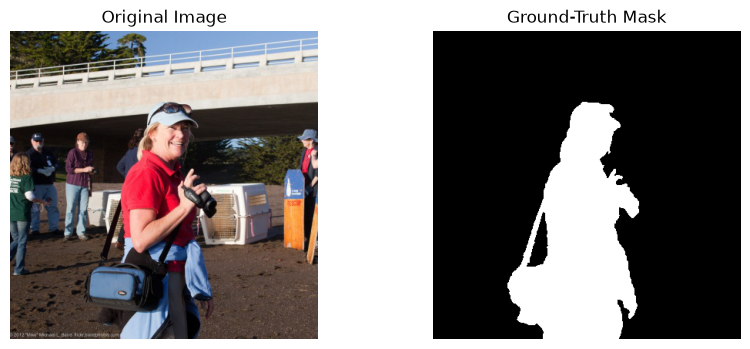

In [8]:
# Visualize a sample image and its ground-truth mask

image_path = dev_images[0]
mask_path = Path("data/masks") / f"{image_path.stem}.png"

image = cv2.imread(str(image_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Original Image")

axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Ground-Truth Mask")

for ax in axes:
    ax.axis("off")

plt.show()

### GrabCut Implementation

In [9]:
# Apply GrabCut with an automatically generated bounding rectangle

image_path = dev_images[0]
image = cv2.imread(str(image_path))

height, width = image.shape[:2]

# Calculate 10% padding
padding_x = int(0.1 * width)
padding_y = int(0.1 * height)

# Define bounding rectangle (x, y, width, height)
rect = (
    padding_x,
    padding_y,
    width - 2 * padding_x,
    height - 2 * padding_y
)

# Initialize GrabCut
mask = np.zeros((height, width), dtype=np.uint8)
bg_model = np.zeros((1, 65), dtype=np.float64)
fg_model = np.zeros((1, 65), dtype=np.float64)

# Run GrabCut for 5 iterations
cv2.grabCut(
    image, mask, rect,
    bg_model, fg_model,
    5, cv2.GC_INIT_WITH_RECT
)

# Convert GrabCut labels to a binary mask
grabcut_mask = np.where(
    (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
    255, 0
).astype(np.uint8)

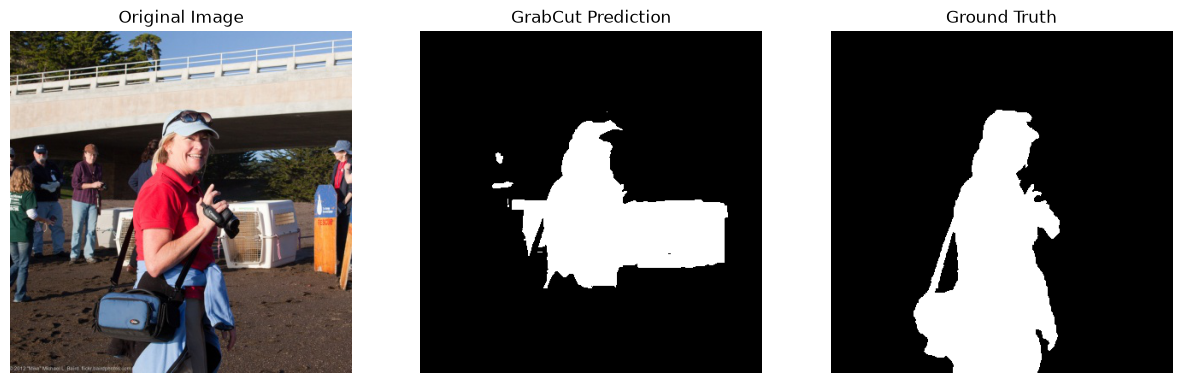

In [10]:
# Visualize the prediction
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original Image")

axes[1].imshow(grabcut_mask, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("GrabCut Prediction")

axes[2].imshow(
    cv2.imread(
        str(Path("data/masks") / f"{image_path.stem}.png"),
        cv2.IMREAD_GRAYSCALE
    ),
    cmap="gray"
)
axes[2].set_title("Ground Truth")

for ax in axes:
    ax.axis("off")

plt.show()

In [12]:
### GrabCut Parameter Tuning
def run_grabcut(image, padding=0.1, iterations=5):
    height, width = image.shape[:2]

    # Calculate rectangle padding
    px = int(padding * width)
    py = int(padding * height)

    rect = (px, py, width - 2*px, height - 2*py)

    # Initialize GrabCut
    mask = np.zeros((height, width), dtype=np.uint8)
    bg_model = np.zeros((1, 65), dtype=np.float64)
    fg_model = np.zeros((1, 65), dtype=np.float64)

    # Run GrabCut
    cv2.grabCut(
        image, mask, rect,
        bg_model, fg_model,
        iterations, cv2.GC_INIT_WITH_RECT
    )

    # Convert to binary mask
    return np.where(
        (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

In [13]:
# Experiment with different configurations
mask1 = run_grabcut(image, padding=0.05, iterations=3)
mask2 = run_grabcut(image, padding=0.10, iterations=5)
mask3 = run_grabcut(image, padding=0.15, iterations=10)

In [14]:
# Calculate IoU between predicted and ground-truth masks

def calculate_iou(predicted, ground_truth):
    pred = predicted > 127
    gt = ground_truth > 127

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    return intersection / union if union > 0 else 1.0

In [20]:
# Load ground-truth mask for the selected dev image
gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

print(f"Padding 5%,  3 iterations:, IoU: {calculate_iou(mask1, gt_mask)}")
print(f"Padding 10%, 5 iterations:, IoU: {calculate_iou(mask2, gt_mask)}")
print(f"Padding 15%, 10 iterations:, IoU: {calculate_iou(mask3, gt_mask)}")

Padding 5%,  3 iterations:, IoU: 0.34545415586363537
Padding 10%, 5 iterations:, IoU: 0.33549899531145344
Padding 15%, 10 iterations:, IoU: 0.3530491095520777


In [ ]:
# GrabCut Parameter Tuning: Broad Search

import itertools
import pandas as pd

def evaluate_configurations(configurations):
    results = []

    for padding, iterations in configurations:
        scores = []

        for image_path in dev_images:
            image = cv2.imread(str(image_path))
            mask_path = Path("data/masks") / f"{image_path.stem}.png"
            gt_mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)

            if image is None or gt_mask is None:
                raise ValueError(f"Could not load {image_path}")

            predicted = run_grabcut(image, padding, iterations)
            scores.append(calculate_iou(predicted, gt_mask))

        mean_iou = np.mean(scores)

        results.append({
            "padding": padding,
            "iterations": iterations,
            "mean_iou": mean_iou
        })

        print(f"Padding: {padding:.0%}, "
              f"Iterations: {iterations}, "
              f"Mean IoU: {mean_iou:.4f}", flush=True)

    return pd.DataFrame(results)


# Broad search
broad_paddings = [0.01, 0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25]
broad_iterations = [1, 3, 5, 10]

broad_configs = list(itertools.product(
    broad_paddings, broad_iterations
))

print("Starting broad search...")
broad_results = evaluate_configurations(broad_configs)

best_broad = broad_results.loc[broad_results["mean_iou"].idxmax()]

print("\nBest Broad Search Configuration:")
print(best_broad)

Padding: 5%, Iterations: 3, Mean IoU: 0.6080, Successful: 700/700
Padding: 5%, Iterations: 5, Mean IoU: 0.6141, Successful: 700/700
Padding: 5%, Iterations: 10, Mean IoU: 0.6147, Successful: 700/700
Padding: 10%, Iterations: 3, Mean IoU: 0.6023, Successful: 700/700
Padding: 10%, Iterations: 5, Mean IoU: 0.6141, Successful: 700/700


KeyboardInterrupt: 

In [ ]:
# GrabCut Parameter Tuning: Fine Search

best_padding = best_broad["padding"]

fine_paddings = np.round(
    np.arange(
        max(0.01, best_padding - 0.03),
        min(0.45, best_padding + 0.03) + 0.001,
        0.01
    ), 3
)

fine_iterations = [3, 5, 10, 15]

fine_configs = [
    (float(p), i)
    for p, i in itertools.product(fine_paddings, fine_iterations)
    if not any(
        abs(p - bp) < 1e-9 and i == bi
        for bp, bi in broad_configs
    )
]

print("Starting fine search...")
fine_results = evaluate_configurations(fine_configs)


# Combine results and select best configuration
all_results = pd.concat(
    [broad_results, fine_results],
    ignore_index=True
)

all_results = all_results.sort_values(
    "mean_iou", ascending=False
)

best = all_results.iloc[0]

print("\n===== BEST GRABCUT CONFIGURATION =====")
print(f"Padding: {best['padding']:.1%}")
print(f"Iterations: {int(best['iterations'])}")
print(f"Mean Dev IoU: {best['mean_iou']:.4f}")

# Save results
all_results.to_csv("grabcut_tuning_results.csv", index=False)